In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 50)
sns.set_style('whitegrid')

DATA_DIR = Path('data')

reviews = pd.read_csv(DATA_DIR / 'olist_order_reviews_dataset.csv')

orders = pd.read_csv(DATA_DIR / 'olist_orders_dataset.csv')

customers = pd.read_csv(DATA_DIR / 'olist_customers_dataset.csv')

print(f'評論數：{len(reviews):,}')
print(f'訂單數：{len(orders):,}')
print(f'顧客數：{len(customers):,}')

評論數：99,224
訂單數：99,441
顧客數：99,441


In [2]:
negative_reviews = reviews[reviews['review_score'] < 3].copy()

negative_reviews['full_text'] = (
    negative_reviews['review_comment_title'].fillna('')
    + ' '
    + negative_reviews['review_comment_message'].fillna('')
)

negative_reviews['full_text'] = (
    negative_reviews['full_text']
    .str.lower()
    .str.replace(r'\s+', ' ', regex = True)
    .str.strip()
)

text_negative_reviews = negative_reviews[negative_reviews['full_text'] != ''].copy()

print(f'負評數：{len(negative_reviews):,}')
print(f'有文字的負評數：{len(text_negative_reviews):,}')

負評數：14,575
有文字的負評數：10,994


In [3]:
date_columns = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]

for col in date_columns:
    orders[col] = pd.to_datetime(orders[col],errors = 'coerce') #errors='coerce' 若日期無法轉換就改成 NaT，而不是整段程式報錯

In [4]:
orders['delay_days'] = (orders['order_delivered_customer_date'] - orders['order_estimated_delivery_date']).dt.days

In [5]:
orders['delivery_status'] = np.select( 
    [
        orders['order_delivered_customer_date'].isna(),
        orders['delay_days'] > 0,
        orders['delay_days'] <= 0
    ],
    [
        'no_delivery_data',
        'late',
        'on_time'
    ],
    default = 'unknown'
)


In [6]:
orders[
    [
        'order_id',
        'delay_days',
        'delivery_status'
    ]
].head()

,order_id,delay_days,delivery_status
0,e481f51cbdc54678b7cc49136f2d6af7,-8.0,on_time
1,53cdb2fc8bc7dce0b6741e2150273451,-6.0,on_time
2,47770eb9100c2d0c44946d9cf07ec65d,-18.0,on_time
3,949d5b44dbf5de918fe9c16f97b45f8a,-13.0,on_time
4,ad21c59c0840e6cb83a9ceb5573f8159,-10.0,on_time


In [7]:
orders_with_customer = orders.merge(
    customers[
        [
            'customer_id',
            'customer_unique_id',
            'customer_state'
        ]
    ],
    on = 'customer_id',
    how = 'left'
)


In [8]:
review_orders = text_negative_reviews.merge(
    orders_with_customer[
        [
            'order_id',
            'customer_state',
            'order_status',
            'order_delivered_customer_date',
            'order_estimated_delivery_date',
            'delay_days',
            'delivery_status'
        ]
    ],
    on = 'order_id',
    how = 'left'
)

review_orders = (
    review_orders
    .drop_duplicates(subset='review_id')
    .copy()
)

In [9]:
print(f'資料列數：{len(review_orders):,}')
print(f'評論 ID 數：{review_orders["review_id"].nunique():,}')

資料列數：10,861
評論 ID 數：10,861


In [10]:
delivery_keyword_map = {
    'delivery_delay': [#問題類型
        'lento', #涵蓋的關鍵字
        'demora',
        'demorou',
        'atraso',
        'atrasada',
        'atrasado',
        'prazo',
        'entreg'
    ],

    'not_received': [
        'não chegou',
        'nunca chegou',
        'não recebi',
        'não veio',
        'perdido',
        'extraviado'
    ],

    'delivery_damage': [
        'quebrado',
        'danificado',
        'amassado',
        'avariado',
        'embalagem'
    ],

    'tracking_or_carrier': [
        'correios',
        'transportadora',
        'rastreamento',
        'rastreio'
    ]
}

def classify_delivery_issue(text):
    if not text or text.strip() == '':
        return []

    matched_issues = []

    for issue , keywords in delivery_keyword_map.items():
        if any(keyword in text for keyword in keywords):
            matched_issues.append(issue)

    return matched_issues

In [11]:
review_orders['delivery_issue_type'] = (
    review_orders['full_text']
    .apply(classify_delivery_issue)
)

review_orders['has_delivery_issue'] = (
    review_orders['delivery_issue_type']
    .apply(len)
    .gt(0) #greater than 0
)

print(review_orders['has_delivery_issue'].value_counts())

has_delivery_issue
True     5724
False    5137
Name: count, dtype: int64


In [12]:
delivery_issue_long = (
    review_orders[
        [
            'review_id',
            'review_score',
            'delivery_status',
            'delay_days',
            'delivery_issue_type'
        ]
    ]
    .explode('delivery_issue_type')
)

delivery_issue_long = (
    delivery_issue_long
    .dropna(subset=['delivery_issue_type'])
)

issue_summary = (
    delivery_issue_long
    .groupby('delivery_issue_type')
    .agg(
        review_count = ('review_id', 'nunique'),
        avg_score = ('review_score', 'mean')
    )
    .reset_index()
)

In [13]:
total_text_negative_reviews = (
    review_orders['review_id'].nunique()
)

issue_summary['pct_of_text_negative'] = (issue_summary['review_count']/ total_text_negative_reviews * 100).round(1)

issue_summary = issue_summary.sort_values('review_count', ascending = False)

issue_summary

,delivery_issue_type,review_count,avg_score,pct_of_text_negative
1,delivery_delay,3728,1.195547,34.3
2,not_received,2290,1.127074,21.1
3,tracking_or_carrier,451,1.221729,4.2
0,delivery_damage,360,1.230556,3.3


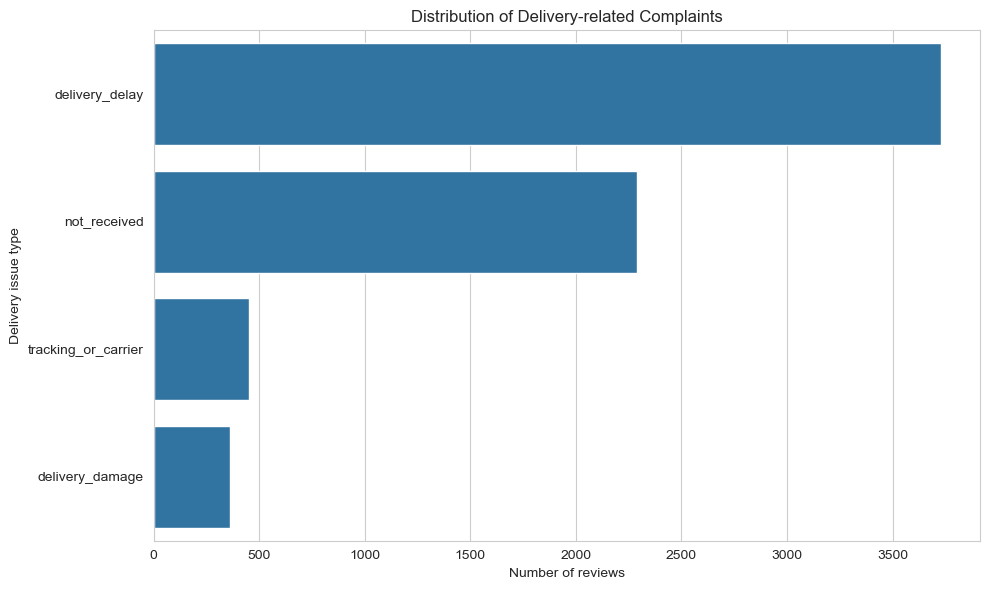

In [14]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data = issue_summary,
    x = 'review_count',
    y = 'delivery_issue_type'
)

plt.xlabel('Number of reviews')
plt.ylabel('Delivery issue type')
plt.title('Distribution of Delivery-related Complaints')
plt.tight_layout()
plt.show()

In [15]:
delay_data = review_orders[
    review_orders['delay_days'].notna()
].copy()

delay_data['delay_days'].describe()

count    9265.000000
mean       -5.899083
std        15.540279
min       -69.000000
25%       -15.000000
50%        -9.000000
75%         4.000000
max       175.000000
Name: delay_days, dtype: float64

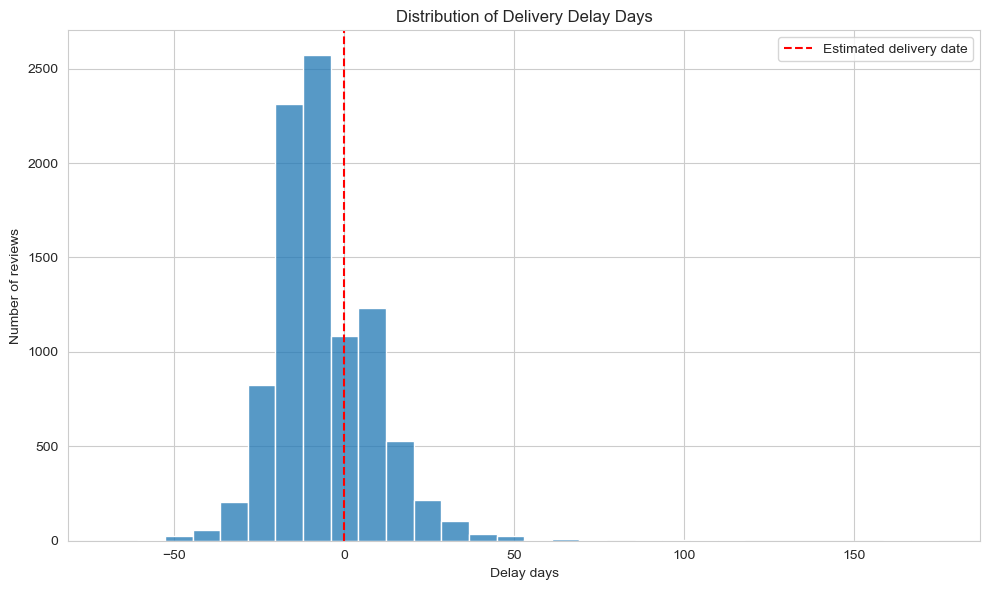

In [16]:
plt.figure(figsize = (10, 6))

sns.histplot(
    data = delay_data,
    x = 'delay_days',
    bins = 30
)

plt.axvline(
    x = 0,
    color = 'red',
    linestyle = '--',
    label = 'Estimated delivery date'
)

plt.xlabel('Delay days')
plt.ylabel('Number of reviews')
plt.title('Distribution of Delivery Delay Days')
plt.legend()
plt.tight_layout()
plt.show()

In [17]:
delivery_comparison_count = pd.crosstab(
    review_orders['delivery_status'],
    review_orders['has_delivery_issue']
)

delivery_comparison_count


has_delivery_issue,False,True
delivery_status,,
late,672,2098
no_delivery_data,586,1010
on_time,3879,2616


In [18]:
delivery_comparison_pct = pd.crosstab(
    review_orders['delivery_status'],
    review_orders['has_delivery_issue'],
    normalize = 'index' 
) * 100

delivery_comparison_pct.round(1)

has_delivery_issue,False,True
delivery_status,,
late,24.3,75.7
no_delivery_data,36.7,63.3
on_time,59.7,40.3


In [19]:
delivery_comparison_pct = (
    delivery_comparison_pct
    .rename(columns = {
        False: 'no_delivery_complaint_pct',
        True: 'delivery_complaint_pct'
    })
    .reset_index()
)

delivery_comparison_pct

has_delivery_issue,delivery_status,no_delivery_complaint_pct,delivery_complaint_pct
0,late,24.259928,75.740072
1,no_delivery_data,36.716792,63.283208
2,on_time,59.722864,40.277136


In [20]:
review_orders['delay_bucket'] = np.select(
    [
        review_orders['delay_days'].isna(),
        review_orders['delay_days'] <= 0,
        review_orders['delay_days'] <= 3,
        review_orders['delay_days'] <= 7,
        review_orders['delay_days'] > 7
    ],
    [
        'no_delivery_data',
        'on_time_or_early',
        'late_1_to_3_days',
        'late_4_to_7_days',
        'late_over_7_days'
    ],
    default = 'unknown'
)

In [21]:
delay_bucket_summary = (
    review_orders
    .groupby('delay_bucket', sort=False)
    .agg(
        review_count = ('review_id', 'nunique'),
        delivery_complaint_count = (
            'has_delivery_issue',
            'sum'
        ),
        avg_score = ('review_score', 'mean')
    )
    .reset_index()
)

delay_bucket_summary['delivery_complaint_rate'] = (delay_bucket_summary['delivery_complaint_count'] / delay_bucket_summary['review_count'] * 100).round(1)

delay_bucket_summary

,delay_bucket,review_count,delivery_complaint_count,avg_score,delivery_complaint_rate
0,late_over_7_days,1540,1191,1.109091,77.3
1,no_delivery_data,1596,1010,1.092732,63.3
2,on_time_or_early,6495,2616,1.253272,40.3
3,late_4_to_7_days,800,615,1.116250,76.9
4,late_1_to_3_days,430,292,1.195349,67.9


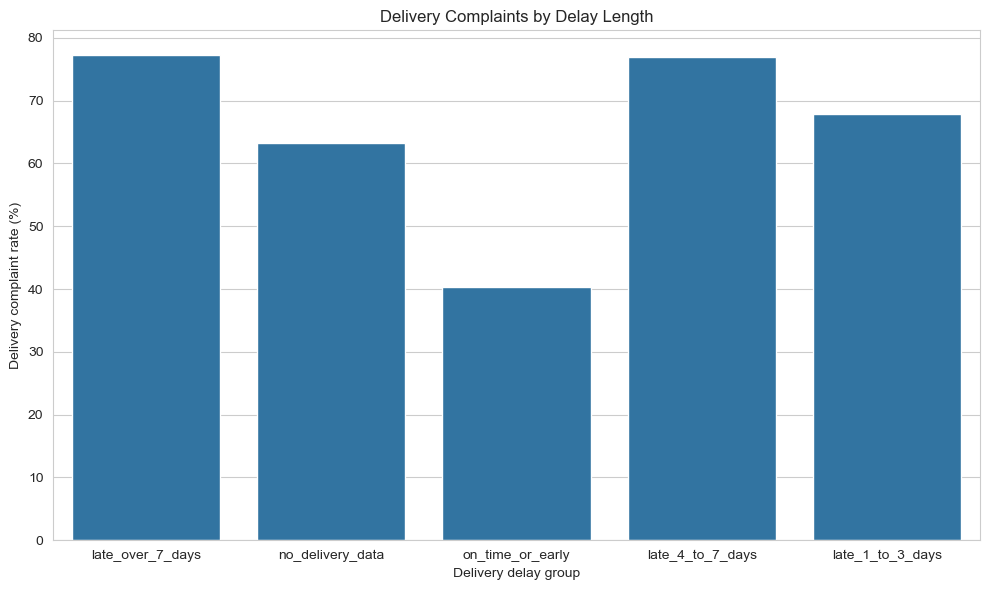

In [22]:
plt.figure(figsize = (10, 6))

sns.barplot(
    data = delay_bucket_summary,
    x = 'delay_bucket',
    y = 'delivery_complaint_rate'
)

plt.xlabel('Delivery delay group')
plt.ylabel('Delivery complaint rate (%)')
plt.title('Delivery Complaints by Delay Length')
plt.tight_layout()
plt.show()